# Weekly project
This weeks weekly project is a continuation of last weeks exercises.

You are to make a handwritten number classifier. Where we will be using the [mnist dataset](https://en.wikipedia.org/wiki/MNIST_database).

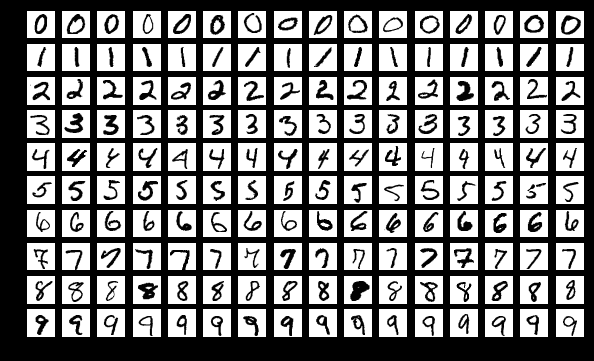

**Create a program that given an image from the mnist dataset.**
- You are free to use any algorithm you want to achieve this.
- It should be able to given a number classify what number it is.
- Accuracy should at least be 80%

If you decide to use a svm make sure you also use dimensionality reduction. SVM of the full mnist dataset will take around 4-8 hours depending on your pc.



**Challange:**
- Try to reach 98% accuracy.
- Try to classify faces with the labeled wild faces dataset [lwf](http://vis-www.cs.umass.edu/lfw/)
```{Python}
from sklearn.datasets import fetch_lfw_people
lfw_people = fetch_lfw_people(min_faces_per_person=70, resize=0.4)
```

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import time
import datetime as dt
from sklearn.decomposition import PCA
from sklearn import datasets, svm, metrics
from sklearn.datasets import fetch_openml

import ssl
ssl._create_default_https_context = ssl._create_unverified_context
mnist = fetch_openml('mnist_784', version=1)

images = mnist.data.to_numpy()
targets = mnist.target.to_numpy()

print(images.shape)
print(targets.shape)

(70000, 784)
(70000,)


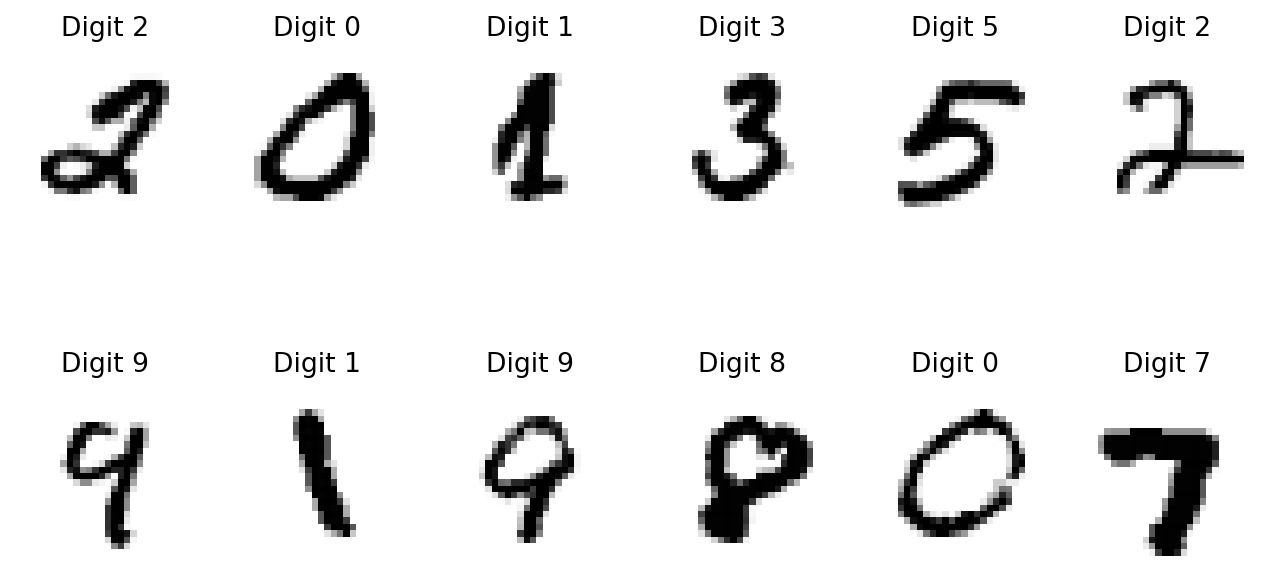

In [3]:
def show_some_digits(images, targets, sample_size=24, title_text='Digit {}' ):
    '''
    Visualize random digits in a grid plot
    images - array of flatten gidigs [:,784]
    targets - final labels
    '''
    nsamples=sample_size
    rand_idx = np.random.choice(images.shape[0], nsamples)
    images_and_labels = list(zip(images[rand_idx], targets[rand_idx]))


    img = plt.figure(1, figsize=(10, 5), dpi=160)
    for index, (image, label) in enumerate(images_and_labels):
        plt.subplot(math.ceil(nsamples/6.0), 6, index + 1)
        plt.axis('off')
        #each image is flat, we have to reshape to 2D array 28x28-784
        plt.imshow(image.reshape(28,28), cmap=plt.cm.gray_r, interpolation='nearest')
        plt.title(title_text.format(label))
    plt.show()

# draw 12 images along with their labels
show_some_digits(images, targets, 12)

Entrenado en 1.0 s
Accuracy train: 0.9998
Accuracy test:  0.9779285714285715


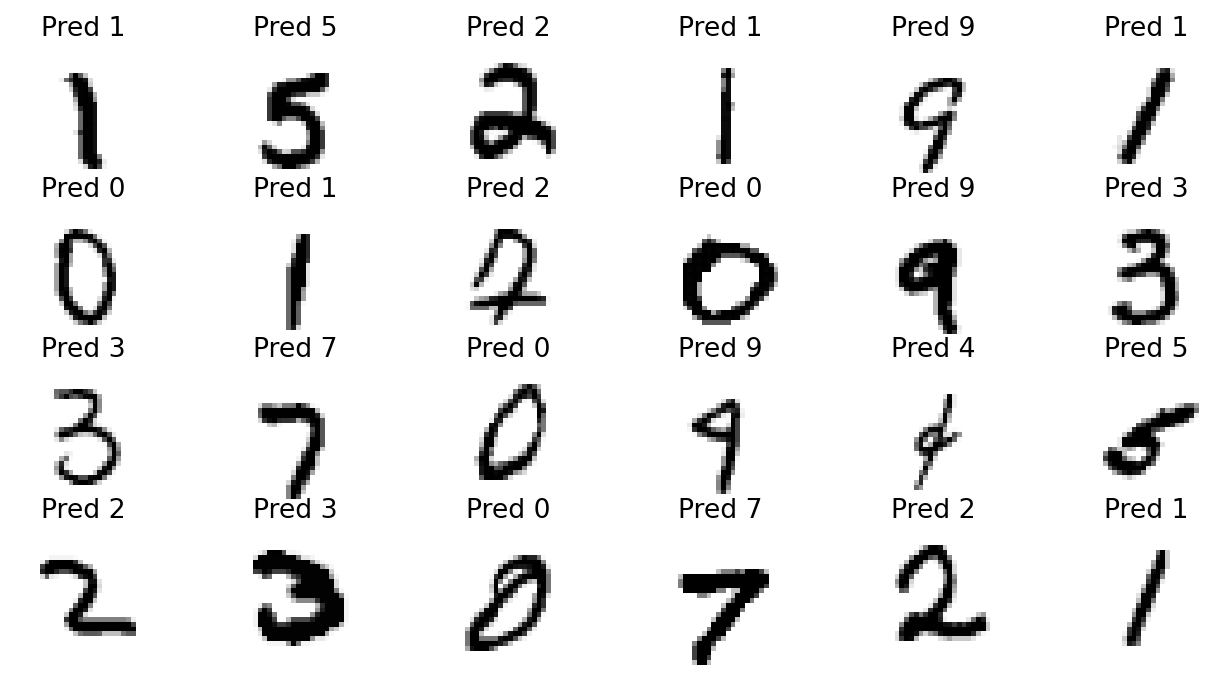

In [17]:
# =====================================================================
# MNIST handwritten digit classifier (PCA + SVM)
# =====================================================================
# Goal: classify digits 0-9 with at least 80% accuracy.
# 70,000 images of 28x28 pixels -> each image is a vector of 784 values.
#
# 1. Split first (80/20 -> 56,000 train / 14,000 test) so the test set
#    is never used when fitting PCA or the SVM (no data leakage).
# 2. PCA 784 -> 50 dims: an SVM on raw pixels takes hours, and most
#    pixels are redundant. 50 components keep ~80% of the variance.
#    Fitted on train only, then applied to test.
# 3. SVM with RBF kernel: digits are not linearly separable, so a
#    curved boundary works better. C=10, gamma set automatically.
# 4. Trained on the first n samples to keep it fast. Test accuracy is
#    measured on 14,000 unseen images -> reliable estimate.
#
# Parameters and what happens when they change:
# - n: higher -> better accuracy but slower training (~n^2).
#      Values above 56,000 just use the whole train set.
# - PCA(50): more components -> more information kept, slower training,
#      small accuracy gain. Too few (e.g. 3) -> digits overlap, accuracy drops.
# - C: higher -> fits the training data more closely (risk of overfitting).
#      Lower -> smoother boundary, more training errors allowed.
# - gamma: higher -> very curved boundary, risk of overfitting.
#      Lower -> smoother boundary, risk of underfitting.
# - kernel='linear': faster but lower accuracy, digits aren't linearly separable.
# - test_size: larger -> more reliable test accuracy, fewer samples to train.
# - random_state: changes which images go to train/test -> small changes in accuracy.
# =====================================================================

import numpy as np
import sklearn as sk
from sklearn import datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from matplotlib import pyplot as plt
from sklearn.decomposition import PCA
from mpl_toolkits.mplot3d import Axes3D
import pandas as pd


X_train, X_test, Y_train, Y_test = train_test_split(
    images, targets, test_size=0.2, random_state=42, stratify=targets)

pca = PCA(50)


# 2) Split -> normalizar (scaler ajustado solo con train)


X_train_p = pca.fit_transform(X_train)
X_test_p  = pca.transform(X_test)

n=60000
t0 = time.time()
# 3) Entrenar y evaluar
clf = SVC(kernel='rbf', C=10, gamma='scale').fit(X_train_p[:n], Y_train[:n])
print(f"Entrenado en {time.time()-t0:.1f} s")
print("Accuracy train:", clf.score(X_train_p[:n], Y_train[:n]))
print("Accuracy test: ", clf.score(X_test_p, Y_test))

show_some_digits(X_test, clf.predict(X_test_p), title_text='Pred {}')
###